<a href="https://colab.research.google.com/github/Sahana14082003/AML/blob/main/Lab2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset:
    mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  worst perimeter  \
0 

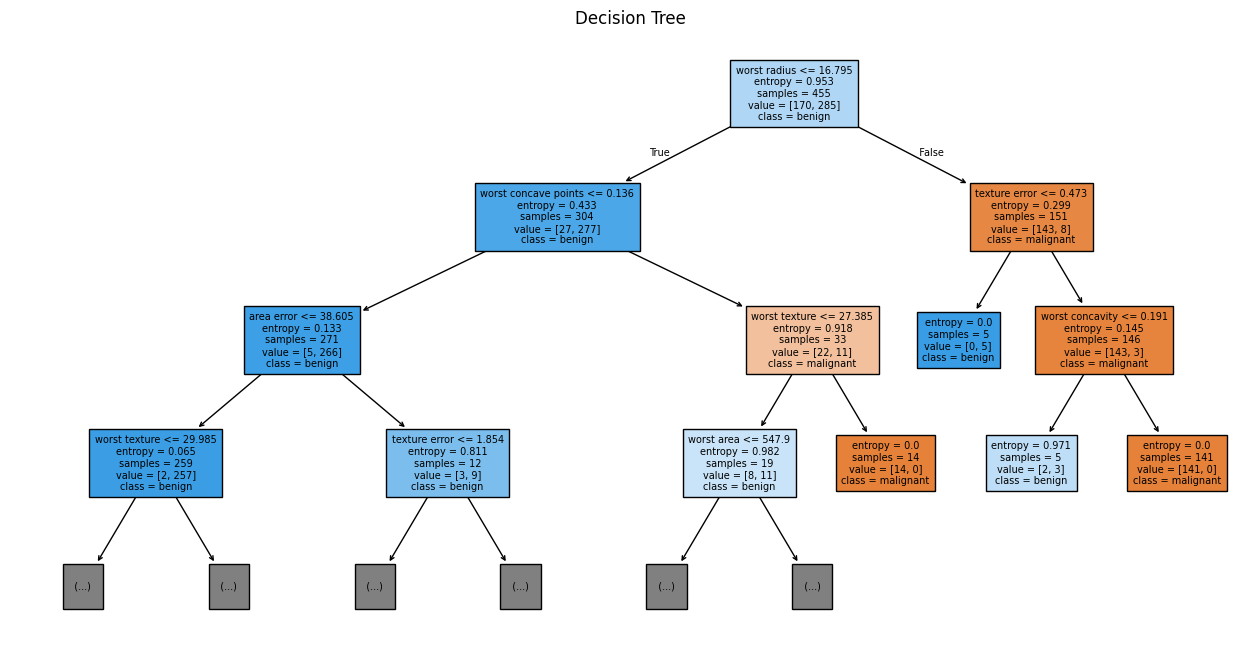

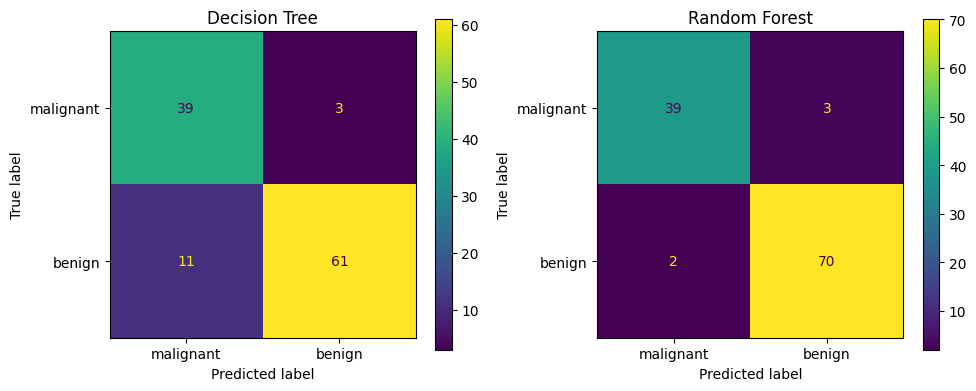


Top 10 Important Features:
 worst area              0.140016
worst concave points    0.129530
worst radius            0.097696
mean concave points     0.090885
worst perimeter         0.072226
mean perimeter          0.069574
mean radius             0.068676
mean concavity          0.057638
mean area               0.049172
worst concavity         0.034340
dtype: float64


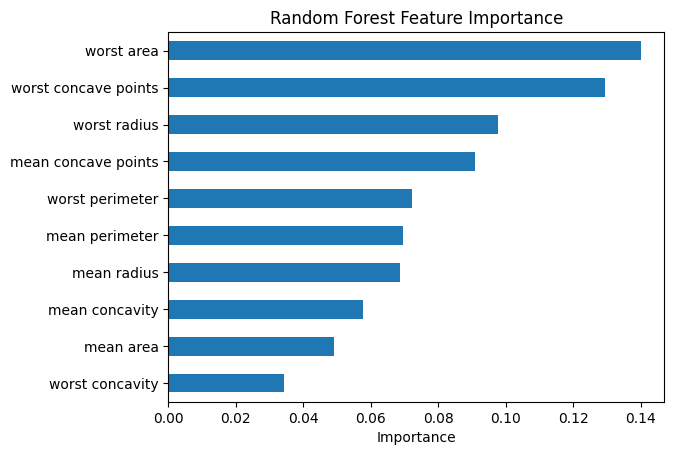

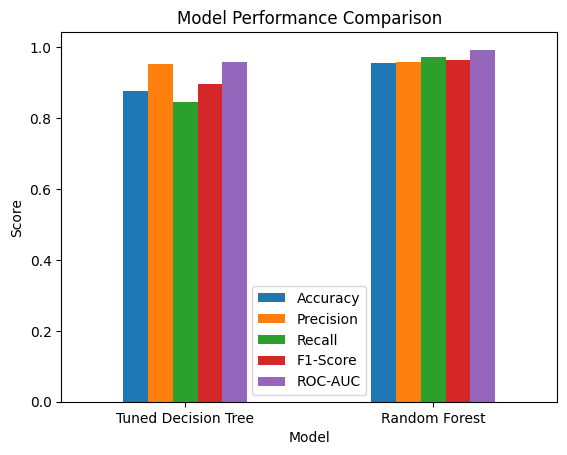

In [3]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, roc_auc_score,
                             ConfusionMatrixDisplay)

# Load dataset
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print("Dataset:\n", X.head())
print("\nDataset Shape:", X.shape)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Decision Tree Classifier
start = time.time()
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)
dt_train_time = time.time() - start

start = time.time()
dt_pred = dt.predict(X_test)
dt_pred_time = time.time() - start

# Tune Decision Tree
tuned_dt = DecisionTreeClassifier(
    criterion='entropy',
    max_depth=4,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)
tuned_dt.fit(X_train, y_train)
tuned_pred = tuned_dt.predict(X_test)

# Random Forest Classifier
start = time.time()
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
rf_train_time = time.time() - start

start = time.time()
rf_pred = rf.predict(X_test)
rf_pred_time = time.time() - start

# Evaluation function
def evaluate(name, model, predictions):
    probability = model.predict_proba(X_test)[:, 1]

    print("\n", name)
    print("Accuracy :", accuracy_score(y_test, predictions))
    print("Precision:", precision_score(y_test, predictions))
    print("Recall   :", recall_score(y_test, predictions))
    print("F1 Score :", f1_score(y_test, predictions))
    print("ROC-AUC  :", roc_auc_score(y_test, probability))
    print("Confusion Matrix:\n", confusion_matrix(y_test, predictions))

evaluate("Decision Tree", dt, dt_pred)
evaluate("Tuned Decision Tree", tuned_dt, tuned_pred)
evaluate("Random Forest", rf, rf_pred)

# Model Comparison
results = pd.DataFrame({
    "Model": ["Tuned Decision Tree", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, tuned_pred),
        accuracy_score(y_test, rf_pred)
    ],
    "Precision": [
        precision_score(y_test, tuned_pred),
        precision_score(y_test, rf_pred)
    ],
    "Recall": [
        recall_score(y_test, tuned_pred),
        recall_score(y_test, rf_pred)
    ],
    "F1-Score": [
        f1_score(y_test, tuned_pred),
        f1_score(y_test, rf_pred)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, tuned_dt.predict_proba(X_test)[:, 1]),
        roc_auc_score(y_test, rf.predict_proba(X_test)[:, 1])
    ]
})

print("\nModel Comparison:\n", results.round(4))

print("\nTraining and Prediction Time:")
print("Decision Tree:", dt_train_time, dt_pred_time)
print("Random Forest:", rf_train_time, rf_pred_time)

# Decision Tree Visualization
plt.figure(figsize=(16, 8))
plot_tree(tuned_dt, feature_names=data.feature_names,
          class_names=data.target_names, filled=True,
          max_depth=3, fontsize=7)
plt.title("Decision Tree")
plt.show()

# Confusion Matrices
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, tuned_pred, display_labels=data.target_names, ax=ax[0]
)
ax[0].set_title("Decision Tree")

ConfusionMatrixDisplay.from_predictions(
    y_test, rf_pred, display_labels=data.target_names, ax=ax[1]
)
ax[1].set_title("Random Forest")

plt.tight_layout()
plt.show()

# Feature Importance
importance = pd.Series(
    rf.feature_importances_, index=data.feature_names
).sort_values(ascending=False)

print("\nTop 10 Important Features:\n", importance.head(10))

importance.head(10).sort_values().plot(kind='barh')
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.show()

# Performance Comparison Graph
results.set_index("Model").drop(columns=[]).plot(
    x="Accuracy" if False else None, kind="bar"
)
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.show()
